In [42]:
# importing libraries
import numpy as np 
import seaborn as sns
from sklearn.metrics import confusion_matrix
import tensorflow
from tensorflow import keras
from keras.layers import Conv2D, Flatten, AveragePooling2D, Input, UpSampling2D, Conv2DTranspose
from keras import Sequential, Model
from keras.datasets import mnist

In [2]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train, x_test = x_train/255, x_test/255

## Encoder - Decoder

### Encoder

In [3]:
input_img = Input(shape=(28, 28, 1))

l1 = Conv2D(8, kernel_size=(3, 3), activation='tanh', padding='valid')(input_img)
p1 = AveragePooling2D(pool_size=(2,2), strides=2, padding='valid')(l1)

l2 = Conv2D(16, kernel_size=(3, 3), activation='relu', padding='valid')(p1)
p2 = AveragePooling2D(pool_size=(2, 2), strides=2, padding='valid')(l2)

encoder = Model(input_img, p2, name="encoder")
encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┓
┃ Layer (type)           ┃ Output Shape    ┃   Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━┩
│ input_layer            │ (None, 28, 28,  │         0 │
│ (InputLayer)           │ 1)              │           │
├────────────────────────┼─────────────────┼───────────┤
│ conv2d (Conv2D)        │ (None, 26, 26,  │        80 │
│                        │ 8)              │           │
├────────────────────────┼─────────────────┼───────────┤
│ average_pooling2d      │ (None, 13, 13,  │         0 │
│ (AveragePooling2D)     │ 8)              │           │
├────────────────────────┼─────────────────┼───────────┤
│ conv2d_1 (Conv2D)      │ (None, 11, 11,  │     1,168 │
│                        │ 16)             │           │
├────────────────────────┼─────────────────┼───────────┤
│ average_pooling2d_1    │ (None, 5, 5,    │         0 │
│ (AveragePooling2D)     │ 16)             │           │
└────────────────────────┴─────────────────┴───────────┘

 Total params: 1,248 (4.88 KB)

 Trainable params: 1,248 (4.88 KB)

 Non-trainable params: 0 (0.00 B)

### Decoder

In [4]:
dinput_img = Input(shape=(5, 5, 16))

d1 = Conv2D(16, kernel_size=(3, 3), activation='relu', padding='same')(dinput_img)
u1 = UpSampling2D(size=(2, 2))(d1)

d2 = Conv2D(8, kernel_size=(3, 3), activation='relu', padding='same')(u1)
u2 = UpSampling2D(size=(2, 2))(d2)

output = Conv2DTranspose(1, kernel_size=(9, 9), padding='valid', activation='sigmoid')(u2)

decoder = Model(dinput_img, output, name='decoder')
decoder.summary()

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┓
┃ Layer (type)           ┃ Output Shape    ┃   Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━┩
│ input_layer_1          │ (None, 5, 5,    │         0 │
│ (InputLayer)           │ 16)             │           │
├────────────────────────┼─────────────────┼───────────┤
│ conv2d_2 (Conv2D)      │ (None, 5, 5,    │     2,320 │
│                        │ 16)             │           │
├────────────────────────┼─────────────────┼───────────┤
│ up_sampling2d          │ (None, 10, 10,  │         0 │
│ (UpSampling2D)         │ 16)             │           │
├────────────────────────┼─────────────────┼───────────┤
│ conv2d_3 (Conv2D)      │ (None, 10, 10,  │     1,160 │
│                        │ 8)              │           │
├────────────────────────┼─────────────────┼───────────┤
│ up_sampling2d_1        │ (None, 20, 20,  │         0 │
│ (UpSampling2D)         │ 8)              │           │
├────────────────────────┼─────────────────┼───────────┤
│ conv2d_transpose       │ (None, 28, 28,  │       649 │
│ (Conv2DTranspose)      │ 1)              │           │
└────────────────────────┴─────────────────┴───────────┘

 Total params: 4,129 (16.13 KB)

 Trainable params: 4,129 (16.13 KB)

 Non-trainable params: 0 (0.00 B)

### AutoEncoder

In [5]:
autoencoder_output = decoder(encoder(input_img))

autoencoder = Model(input_img, autoencoder_output, name='auto_encoder')

In [6]:
autoencoder.compile(loss='mse', optimizer='rmsprop')

In [7]:
history = autoencoder.fit(x_train, x_train, batch_size=1000, validation_data=(x_test, x_test), epochs=15)

Epoch 1/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 9s 109ms/step - loss: 0.1097 - val_loss: 0.0622
Epoch 2/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 96ms/step - loss: 0.0539 - val_loss: 0.0458
Epoch 3/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 96ms/step - loss: 0.0405 - val_loss: 0.0355
Epoch 4/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 97ms/step - loss: 0.0322 - val_loss: 0.0285
Epoch 5/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 98ms/step - loss: 0.0269 - val_loss: 0.0254
Epoch 6/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 7s 118ms/step - loss: 0.0237 - val_loss: 0.0221
Epoch 7/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 7s 114ms/step - loss: 0.0213 - val_loss: 0.0203
Epoch 8/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 106ms/step - loss: 0.0196 - val_loss: 0.0187
Epoch 9/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 7s 109ms/step - loss: 0.0182 - val_loss: 0.0178
Epoch 10/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 104ms/step - loss: 0.0170 - val_loss: 0.0168
Epoch 11/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 101ms/step - loss: 0.0160 - val_loss: 0.0156
Epoch 12/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 102ms/step - l

<Axes: >

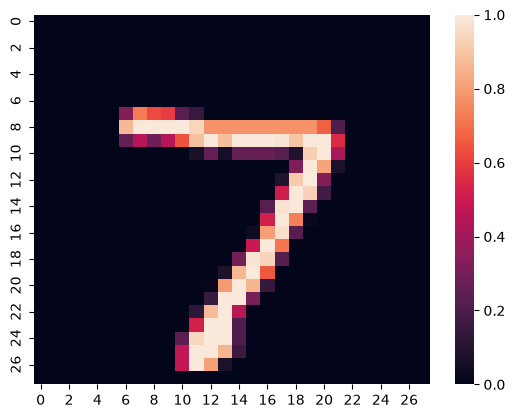

In [8]:
sns.heatmap(x_test[0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 215ms/step


<Axes: >

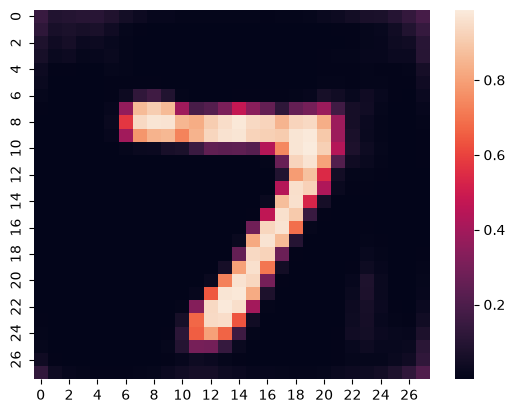

In [9]:
sns.heatmap(autoencoder.predict(x_test[:1]).reshape(28, 28))

## Neural Network

### NN

In [17]:
class Layer:

    def __init__(self, n_inputs, n_neurons):
        self.weights = 0.01 * np.random.randn(n_inputs, n_neurons)
        self.biases = np.zeros((1, n_neurons))

    def forward(self, inputs):
        self.inputs = inputs
        self.outputs = np.dot(self.inputs, self.weights) + self.biases

    def backward(self, dvalues):
        # weights
        self.dweights = np.dot(self.inputs.T, dvalues)
        # inputs
        self.dinputs = np.dot(dvalues, self.weights.T)
        # biases
        self.dbiases = np.sum(dvalues, axis=0, keepdims=True)

In [18]:
class ReLUActivation:
    def forward(self, inputs):
        self.inputs = inputs
        self.outputs = np.maximum(self.inputs, 0)

    def backward(self, dvalues):
        self.dinputs = dvalues.copy()
        self.dinputs[self.inputs<=0] = 0

In [19]:
class SoftmaxActivation:
    def forward(self, inputs):
        exp_values = np.exp(inputs-np.max(inputs, axis=1, keepdims=True))
        self.outputs = exp_values / np.sum(exp_values, axis=1, keepdims=True)

In [20]:
class Loss:
    def calculate_loss(self, y_true, y_pred):
        return np.mean(self.forward(y_true, y_pred))

class CategoricalCrossEntropyLoss(Loss):

    def forward(self, y_true, y_pred):
        # y_true -> one hot encoded
        y_pred_clip = np.clip(y_pred, 1e-7, 1-1e-7)
        # prevent 0 and 1
        correct_confidences = np.sum(y_pred_clip * y_true, axis=1)
        neg_log_liklihoods = - np.log(correct_confidences)

        return neg_log_liklihoods

    def backward(self, dvalues, y_true):
        # y_true -> one hot encoded
        self.dinputs = - y_true/dvalues
        self.dinputs = self.dinputs/len(dvalues)

In [21]:
class SoftMax_CCEL:
    def __init__(self):
        self.activation = SoftmaxActivation()
        self.ccel = CategoricalCrossEntropyLoss()

    def forward(self, inputs, y_true):
        self.activation.forward(inputs)
        self.outputs = self.activation.outputs

        return self.ccel.calculate_loss(y_true, self.outputs)

    def backward(self, dvalues, y_true):
        self.dinputs = dvalues - y_true
        # prediction - true value
        self.dinputs /= len(dvalues)

In [22]:
class AdamOptimizer:
    
    def __init__(self, learning_rate=0.001, decay=0., epsilon=1e-7, beta_1=0.9, beta_2=0.999):
        self.learning_rate = learning_rate
        self.current_learning_rate = learning_rate
        self.decay = decay
        self.iterations = 0
        self.epsilon = epsilon
        self.beta_1 = beta_1
        self.beta_2 = beta_2

    def pre_update_params(self):
        if self.decay:
            self.current_learning_rate = self.learning_rate * (1. / (1. + self.decay * self.iterations))

    # Update parameters
    def update_params(self, layer):
        # If layer does not contain cache arrays, create them filled with zeros
        if not hasattr(layer, 'weight_cache'):
            layer.weight_momentums = np.zeros_like(layer.weights)
            layer.weight_cache = np.zeros_like(layer.weights)
            layer.bias_momentums = np.zeros_like(layer.biases)
            layer.bias_cache = np.zeros_like(layer.biases)

        # Update momentum with current gradients
        layer.weight_momentums = self.beta_1 * layer.weight_momentums + (1 - self.beta_1) * layer.dweights
        layer.bias_momentums = self.beta_1 * layer.bias_momentums + (1 - self.beta_1) * layer.dbiases

        # Get corrected momentum
        # self.iteration is 0 at first pass and we need to start with 1 here
        weight_momentums_corrected = layer.weight_momentums / (1 - self.beta_1 ** (self.iterations + 1))
        bias_momentums_corrected = layer.bias_momentums / (1 - self.beta_1 ** (self.iterations + 1))

        # Update cache with squared current gradients
        layer.weight_cache = self.beta_2 * layer.weight_cache + (1 - self.beta_2) * layer.dweights**2
        layer.bias_cache = self.beta_2 * layer.bias_cache + (1 - self.beta_2) * layer.dbiases**2

        # Get corrected cache
        weight_cache_corrected = layer.weight_cache / (1 - self.beta_2 ** (self.iterations + 1))
        bias_cache_corrected = layer.bias_cache / (1 - self.beta_2 ** (self.iterations + 1))

        # Vanilla SGD parameter update + normalization with square rooted cache
        layer.weights += -self.current_learning_rate * weight_momentums_corrected / (np.sqrt(weight_cache_corrected) + self.epsilon)
        layer.biases += -self.current_learning_rate * bias_momentums_corrected / (np.sqrt(bias_cache_corrected) + self.epsilon)

    # Call once after any parameter updates
    def post_update_params(self):
        self.iterations += 1

### NN Training

In [10]:
x_train_features = encoder.predict(x_train)
x_test_features = encoder.predict(x_test)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [11]:
x_train_features.shape

(60000, 5, 5, 16)

In [14]:
x_train_features = x_train_features.reshape(x_train.shape[0], -1)
x_test_features = x_test_features.reshape(x_test.shape[0], -1)

In [26]:
y_train_encoded = np.eye(10)[y_train]

In [39]:
y_test_encoded = np.eye(10)[y_test]

In [23]:
x_test_features.shape

(10000, 400)

In [49]:
# first layer 
l1 = Layer(400, 128)
af1 = ReLUActivation()
# second layer
l2 = Layer(128, 10)
loss_af = SoftMax_CCEL()

# Adam Optimizer
opt = AdamOptimizer(learning_rate=0.01, decay=1e-5)

epochs = 501

In [50]:
for _ in range(epochs):
    # layer one
    l1.forward(x_train_features)
    af1.forward(l1.outputs)

    # layer two 
    l2.forward(af1.outputs)
    loss = loss_af.forward(l2.outputs, y_train_encoded)

    # predictions
    predictions = np.argmax(loss_af.outputs, axis=1)

    # accuracy
    acc = np.mean(predictions == y_train)

    # backward pass
    loss_af.backward(loss_af.outputs, y_train_encoded)
    l2.backward(loss_af.dinputs)
    af1.backward(l2.dinputs)
    l1.backward(af1.dinputs)

    # optimizers 
    opt.pre_update_params()
    opt.update_params(l1)
    opt.update_params(l2)
    opt.post_update_params()

    if _%10 == 0:
        print('Accuracy', acc, '\nLoss : ', loss, '\nIteration : ', _)

Accuracy 0.09673333333333334 
Loss :  2.3029914444613047 
Iteration :  0
Accuracy 0.75805 
Loss :  0.7626981597122585 
Iteration :  10
Accuracy 0.87465 
Loss :  0.4422348512776802 
Iteration :  20
Accuracy 0.8960833333333333 
Loss :  0.3586728559605678 
Iteration :  30
Accuracy 0.9115666666666666 
Loss :  0.30083641027478214 
Iteration :  40
Accuracy 0.9222 
Loss :  0.26222847656878473 
Iteration :  50
Accuracy 0.9320333333333334 
Loss :  0.2320403374383371 
Iteration :  60
Accuracy 0.9391666666666667 
Loss :  0.20753138194515106 
Iteration :  70
Accuracy 0.94575 
Loss :  0.18641624399822224 
Iteration :  80
Accuracy 0.9512833333333334 
Loss :  0.16782493136917442 
Iteration :  90
Accuracy 0.9561833333333334 
Loss :  0.1516657174292944 
Iteration :  100
Accuracy 0.9587166666666667 
Loss :  0.1415234534690627 
Iteration :  110
Accuracy 0.9615333333333334 
Loss :  0.13321939860770424 
Iteration :  120
Accuracy 0.9644833333333334 
Loss :  0.12251350502469031 
Iteration :  130
Accuracy 0.9

### Model Evaluation

In [52]:
# first layer 
l1.forward(x_test_features)
af1.forward(l1.outputs)

# second layer 
l2.forward(af1.outputs)
loss_test = loss_af.forward(l2.outputs, y_test_encoded)

# prediction 
predictions_test = np.argmax(loss_af.outputs, axis=1)

# accuracy
acc_test = np.mean(predictions_test == y_test)

print('Accuracy : ', acc_test, 'Loss : ', loss_test)

Accuracy :  0.9829 Loss :  0.053908854992244994


<Axes: >

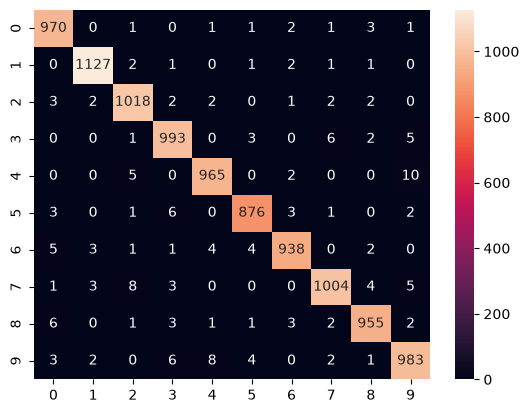

In [53]:
sns.heatmap(confusion_matrix(y_test, predictions_test), annot=True, fmt='d')

In [75]:
def predict_digit(img):

    
    x_features = encoder.predict(np.expand_dims(img, axis=0))
    x_features = x_features.reshape(x_features.shape[0], -1)

    # first layer 
    l1.forward(x_features)
    af1.forward(l1.outputs)
    
    # second layer 
    l2.forward(af1.outputs)
    loss_test = loss_af.forward(l2.outputs, y_test_encoded)
    
    # prediction 
    predictions = np.argmax(loss_af.outputs, axis=1)

    return predictions

<Axes: >

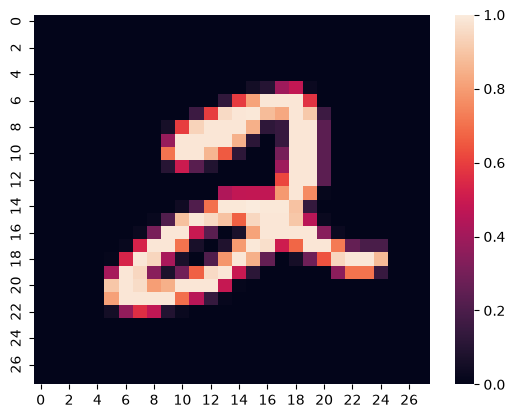

In [55]:
sns.heatmap(x_train[5])

In [76]:
predict_digit(x_train[5])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step


array([2])

## Testing on Real World Data

In [81]:
import matplotlib.pyplot as plt 

In [86]:
import cv2

def invert(img):

    img = cv2.resize(img, (28, 28))
    invert_img = cv2.bitwise_not(img)
    invert_img = np.array(invert_img)/255

    sns.heatmap(invert_img)
    plt.show()

    # invert_img = invert_img.reshape(1, 784)
    
    return invert_img

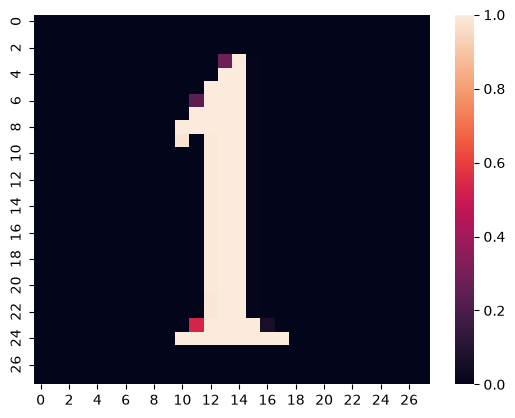

In [93]:
img1 = cv2.imread('img1.png', cv2.IMREAD_GRAYSCALE)
img1 = invert(img1)

In [95]:
predict_digit(img1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


array([1])

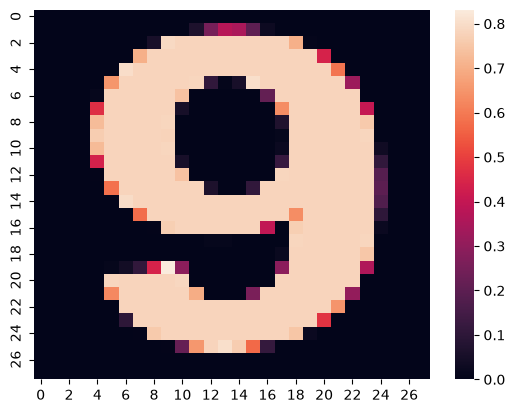

In [97]:
img9 = cv2.imread('img9.png', cv2.IMREAD_GRAYSCALE)
img9 = invert(img9)

In [98]:
predict_digit(img9)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


array([3])